# 02 — Model Training and Evaluation

In this notebook, I trained and compared three CNN models to classify colon histopathology images as benign tissue or adenocarcinoma. I started with a baseline CNN adapted from Li (2025), followed by EfficientNetB3 and ConvNeXt-Tiny using pretrained ImageNet weights.

All three models were trained with the partitions prepared in Notebook 01 and evaluated on the same held-out test set. I compared accuracy, precision, recall, and F1-score to examine both overall performance and errors in the adenocarcinoma class.

**Attribution:** The baseline CNN was adapted from Li's `Detection.ipynb` (2025), available through Harvard Dataverse (DOI: 10.7910/DVN/B7OXBS).

**Notebook sequence:** [01] Dataset preparation → **[02] Model training and evaluation** → [03] Explainability analysis.

**Execution note:** The experiments were performed in Kaggle. The original code and saved outputs were preserved; the models were not retrained for this portfolio revision.

In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for filename in files:
        if filename.endswith(".csv"):
            print(os.path.join(root, filename))

/kaggle/input/notebooks/educatedfish808/01-colon-histopathology-eda/splits/validation.csv
/kaggle/input/notebooks/educatedfish808/01-colon-histopathology-eda/splits/train.csv
/kaggle/input/notebooks/educatedfish808/01-colon-histopathology-eda/splits/test.csv


## 1. Loading the prepared dataset

I loaded the training, validation, and test CSV files created in Notebook 01. Using the same predefined partitions allowed me to compare the models fairly without repeating the splitting procedure.

I also checked the input paths so that the notebook could locate the images attached in Kaggle. If the input dataset is attached under another name, its path may need to be updated.

In [2]:

import os
import pandas as pd

# Path to saved dataset splits
splits_dir = (
    "/kaggle/input/notebooks/educatedfish808/"
    "01-colon-histopathology-eda/splits"
)

# Load the three datasets
train_df = pd.read_csv(f"{splits_dir}/train.csv")
valid_df = pd.read_csv(f"{splits_dir}/validation.csv")
test_df = pd.read_csv(f"{splits_dir}/test.csv")

# Confirm dataset sizes
print("Training:", len(train_df))
print("Validation:", len(valid_df))
print("Testing:", len(test_df))

# Check image paths
print("\nFirst training image exists:",
      os.path.isfile(train_df["filepaths"].iloc[0]))

# Preview
print("\nTraining data preview:")
print(train_df.head())


Training: 7599
Validation: 963
Testing: 963

First training image exists: True

Training data preview:
                                           filepaths          labels  \
0  /kaggle/input/datasets/andrewmvd/lung-and-colo...  adenocarcinoma   
1  /kaggle/input/datasets/andrewmvd/lung-and-colo...  adenocarcinoma   
2  /kaggle/input/datasets/andrewmvd/lung-and-colo...  adenocarcinoma   
3  /kaggle/input/datasets/andrewmvd/lung-and-colo...  adenocarcinoma   
4  /kaggle/input/datasets/andrewmvd/lung-and-colo...  adenocarcinoma   

                                          image_hash             phash  \
0  1681a711d20740a6caea456f6c5c29e3bc94cca9c58a3b...  fd794e0107ae198e   
1  4573a009a0cbdaa38e7d37790c0f3a1e26f83b7c1bcac3...  a93626c343e51eda   
2  1ebe06b91479d5c96922cd3e59006883fd845405c018e2...  bcfa65b688e02327   
3  37d3e8c22c44c30c373528a4e3327df46a81b95076778c...  ca8a55f2416df9a1   
4  56c174e0494b2ad4c66ed1c62b282f277ad0c6c9c8e6c3...  a799ae208eb4bc6c   

   similarity_group

## 2. Image generators and preprocessing

I used Keras image generators to load images in batches and resize them to 224 × 224 pixels. Training images were shuffled, while validation and test images remained in a fixed order so their predictions could be matched to the correct labels.

The images were initially rescaled to 0–1. **Adenocarcinoma was encoded as class 0 and benign tissue as class 1**, which I retained when calculating cancer-specific metrics. The pretrained architectures received additional input rescaling to match their built-in preprocessing.

I did not apply random image augmentation in this training pipeline.

In [3]:

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 20
SEED = 40

# Normalize pixel values to [0, 1]
datagen = ImageDataGenerator(rescale=1.0 / 255)

# Training generator
train_gen = datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepaths",
    y_col="labels",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)

# Validation generator
valid_gen = datagen.flow_from_dataframe(
    dataframe=valid_df,
    x_col="filepaths",
    y_col="labels",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# Test generator
test_gen = datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="filepaths",
    y_col="labels",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("\nClass mapping:", train_gen.class_indices)


Found 7599 validated image filenames belonging to 2 classes.
Found 963 validated image filenames belonging to 2 classes.
Found 963 validated image filenames belonging to 2 classes.

Class mapping: {'adenocarcinoma': 0, 'benign': 1}


## 3. Baseline convolutional neural network

I first trained a baseline CNN to provide a comparison for the pretrained models. Its architecture was adapted from `Detection.ipynb` by Li (2025), rather than developed entirely from scratch.

The CNN contained convolutional, batch-normalization, pooling, and dropout layers, followed by a two-class softmax output. I trained it without pretrained weights using categorical cross-entropy and the Adamax optimizer. Comparing this baseline with EfficientNetB3 and ConvNeXt-Tiny helped me examine whether transfer learning improved classification performance.

The precise changes from Li's original implementation were not independently verified in this review.

In [4]:

from tensorflow.keras import Sequential, layers
from tensorflow.keras.optimizers import Adamax

# Set reproducibility seed
tf.keras.utils.set_random_seed(40)

IMG_SHAPE = (224, 224, 3)
NUM_CLASSES = len(train_gen.class_indices)

def conv_block(filters):
    return Sequential([
        layers.Conv2D(filters, 3, activation="relu", padding="same"),
        layers.Conv2D(filters, 3, activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D()
    ])

def dense_block(units, dropout_rate):
    return Sequential([
        layers.Dense(units, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(dropout_rate)
    ])

cnn_model = Sequential([
    layers.Input(shape=IMG_SHAPE),

    layers.Conv2D(16, 3, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    conv_block(32),
    conv_block(64),
    conv_block(128),
    conv_block(256),

    layers.Flatten(),

    dense_block(256, 0.8),
    dense_block(128, 0.5),
    dense_block(64, 0.3),
    dense_block(32, 0.2),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

cnn_model.compile(
    optimizer=Adamax(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()


I0000 00:00:1792237754.248600      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792237754.252305      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 56, 56, 32)     │        14,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 28, 28, 64)     │        55,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 14, 14, 128)    │       221,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_3 (Sequential)       │ (None, 7, 7, 256)      │       886,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 256)            │     3,212,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_5 (Sequential)       │ (None, 128)            │        33,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_6 (Sequential)       │ (None, 64)             │         8,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_7 (Sequential)       │ (None, 32)             │         2,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,435,170 (16.92 MB)

 Trainable params: 4,433,218 (16.91 MB)

 Non-trainable params: 1,952 (7.62 KB)

### 3.1 Training the baseline model

I trained the baseline CNN for 13 epochs and monitored its validation performance. I then saved the final model for later evaluation. Unlike the pretrained models, this run did not use checkpointing to select an earlier epoch.

In [5]:

# Train the baseline CNN
history_cnn = cnn_model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=13,
    verbose=1
)

# Save the trained model
cnn_model.save("/kaggle/working/baseline_cnn.keras")

print("Baseline CNN training complete.")


Epoch 1/13


2026-10-17 11:50:15.702793: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 11:50:15.842996: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 11:50:16.149641: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 11:50:16.288256: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  2/380 ━━━━━━━━━━━━━━━━━━━━ 22s 61ms/step - accuracy: 0.4000 - loss: 1.0760   

I0000 00:00:1792237823.580336     139 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


266/380 ━━━━━━━━━━━━━━━━━━━━ 18s 166ms/step - accuracy: 0.6179 - loss: 0.8285

2026-10-17 11:51:10.766359: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 11:51:10.906385: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 11:51:11.210123: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 11:51:11.348448: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


380/380 ━━━━━━━━━━━━━━━━━━━━ 103s 224ms/step - accuracy: 0.7008 - loss: 0.6424 - val_accuracy: 0.5742 - val_loss: 0.7446
Epoch 2/13
380/380 ━━━━━━━━━━━━━━━━━━━━ 42s 110ms/step - accuracy: 0.8568 - loss: 0.3405 - val_accuracy: 0.8837 - val_loss: 0.2747
Epoch 3/13
380/380 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - accuracy: 0.9243 - loss: 0.2059 - val_accuracy: 0.9367 - val_loss: 0.1819
Epoch 4/13
380/380 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - accuracy: 0.9425 - loss: 0.1571 - val_accuracy: 0.9688 - val_loss: 0.0896
Epoch 5/13
380/380 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - accuracy: 0.9542 - loss: 0.1288 - val_accuracy: 0.8795 - val_loss: 0.2916
Epoch 6/13
380/380 ━━━━━━━━━━━━━━━━━━━━ 40s 105ms/step - accuracy: 0.9543 - loss: 0.1271 - val_accuracy: 0.9304 - val_loss: 0.1754
Epoch 7/13
380/380 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - accuracy: 0.9632 - loss: 0.1058 - val_accuracy: 0.9979 - val_loss: 0.0182
Epoch 8/13
380/380 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - accuracy: 0.9718 - loss: 0.0846 - va

### 3.2 Examining training and validation curves

I plotted training and validation accuracy and loss to examine how the baseline learned over time. Comparing the two curves also helped me look for possible overfitting.

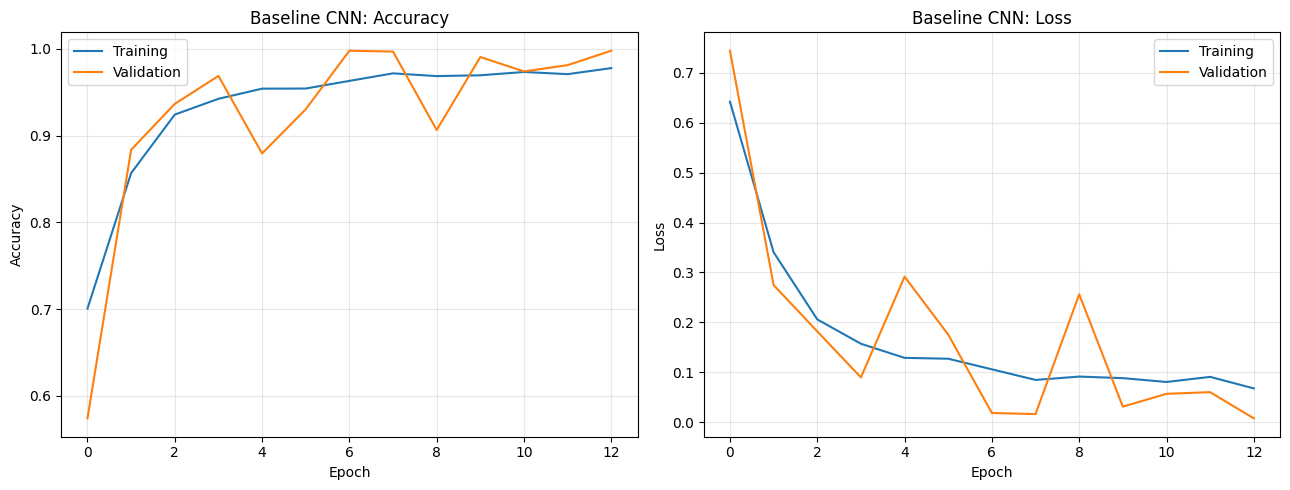

In [6]:

import matplotlib.pyplot as plt

history = history_cnn.history

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy
axes[0].plot(history["accuracy"], label="Training")
axes[0].plot(history["val_accuracy"], label="Validation")
axes[0].set_title("Baseline CNN: Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(history["loss"], label="Training")
axes[1].plot(history["val_loss"], label="Validation")
axes[1].set_title("Baseline CNN: Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 3.3 Validation performance

I evaluated the baseline on the validation partition before comparing it with the pretrained architectures. This provided an initial performance check, but the held-out test set was reserved for the final comparison.

In [7]:

# Evaluate the trained model on validation data
val_loss, val_accuracy = cnn_model.evaluate(
    valid_gen,
    verbose=1
)

print(f"Validation accuracy: {val_accuracy:.4f}")
print(f"Validation loss: {val_loss:.4f}")


49/49 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - accuracy: 0.9979 - loss: 0.0075
Validation accuracy: 0.9979
Validation loss: 0.0075


### 3.4 Confusion matrix and classification report

I examined the confusion matrix and classification report because accuracy alone did not show which class the model struggled to identify. These outputs provided class-specific precision, recall, and F1-scores.

49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 115ms/step


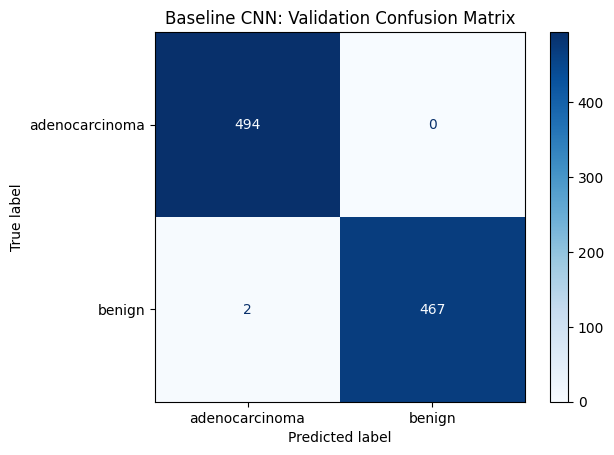

                precision    recall  f1-score   support

adenocarcinoma     0.9960    1.0000    0.9980       494
        benign     1.0000    0.9957    0.9979       469

      accuracy                         0.9979       963
     macro avg     0.9980    0.9979    0.9979       963
  weighted avg     0.9979    0.9979    0.9979       963



In [8]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Ensure predictions start at the first validation image
valid_gen.reset()

# Generate predictions
predictions = cnn_model.predict(valid_gen, verbose=1)

# Convert probabilities into predicted class indices
y_pred = np.argmax(predictions, axis=1)

# Actual class indices
y_true = valid_gen.classes

# Class names in the correct order
class_names = list(valid_gen.class_indices.keys())

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Baseline CNN: Validation Confusion Matrix")
plt.show()

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))


### 3.5 Inspecting incorrect predictions

I displayed examples of the baseline model's incorrect predictions to look for possible patterns in its errors. Visual inspection could not establish why the model made those predictions, so I investigated model explanations separately in Notebook 03.

Incorrect predictions: 2


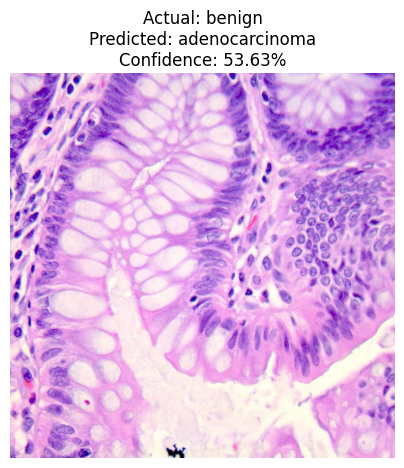

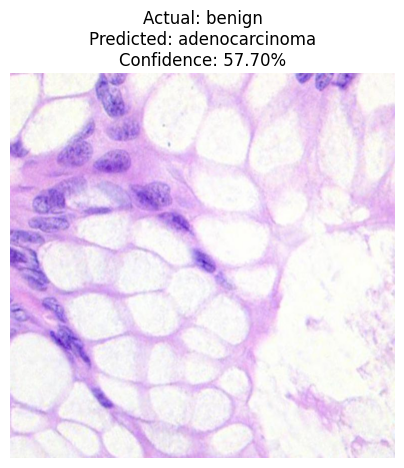

In [9]:

from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Identify incorrect predictions
incorrect_indices = np.where(y_true != y_pred)[0]

print("Incorrect predictions:", len(incorrect_indices))

for idx in incorrect_indices:
    filepath = valid_gen.filepaths[idx]

    with Image.open(filepath) as img:
        plt.figure(figsize=(5, 5))
        plt.imshow(img.convert("RGB"))

    plt.title(
        f"Actual: {class_names[y_true[idx]]}\n"
        f"Predicted: {class_names[y_pred[idx]]}\n"
        f"Confidence: {predictions[idx, y_pred[idx]]:.2%}"
    )

    plt.axis("off")
    plt.show()


## 4. EfficientNetB3: Transfer learning

After training the baseline, I used EfficientNetB3 with pretrained ImageNet weights. I chose transfer learning to build on features learned from other images instead of training a larger network entirely from scratch.

I replaced its classifier with a two-class head and initially froze the pretrained backbone. Because EfficientNetB3 handles its own input normalization, I multiplied the generator's 0–1 image values by 255 before passing them to the backbone.

In [10]:

import tensorflow as tf
from tensorflow.keras import Model, layers
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(40)

# Load pretrained EfficientNetB3 without its ImageNet classifier
effnet_base = EfficientNetB3(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze the pretrained backbone
effnet_base.trainable = False

# Build our new classifier
inputs = layers.Input(shape=(224, 224, 3))

# Existing generator supplies images scaled to [0, 1].
# Keras EfficientNetB3 expects input values in [0, 255]
# because preprocessing is built into the architecture.
x = layers.Rescaling(255.0)(inputs)

x = effnet_base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(2, activation="softmax")(x)

effnet_model = Model(inputs, outputs)

# Compile model
effnet_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

effnet_model.summary()


43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 7, 7, 1536)     │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       196,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,980,529 (41.89 MB)

 Trainable params: 196,994 (769.51 KB)

 Non-trainable params: 10,783,535 (41.14 MB)

### 4.1 Saving the best model during training

I used early stopping and model checkpointing based on validation loss. This allowed me to keep the checkpoint with the lowest observed validation loss rather than relying only on the last epoch.

In [12]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from pathlib import Path

# Create directory for saved models
model_dir = Path("/kaggle/working/models")
model_dir.mkdir(parents=True, exist_ok=True)

# Callbacks for Stage 1
effnet_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(model_dir / "effnet_stage1_best.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
]


### 4.2 Stage 1: Training the classification head

I first trained only the new classification head while keeping the pretrained backbone frozen. This allowed the classifier to adapt to the two colon tissue categories before fine-tuning deeper layers.

In [13]:

# Train the new classification head
history_effnet_stage1 = effnet_model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=10,
    callbacks=effnet_callbacks,
    verbose=1
)

print("EfficientNetB3 Stage 1 training complete.")


Epoch 1/10


2026-10-17 12:35:16.513517: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 12:35:16.658045: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 12:35:17.007859: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 12:35:17.157037: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 12:35:17.987801: E external/local_xla/xla/stream_

 82/380 ━━━━━━━━━━━━━━━━━━━━ 36s 124ms/step - accuracy: 0.8089 - loss: 0.4143

2026-10-17 12:35:51.168450: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 12:35:51.313110: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 12:35:51.660222: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 12:35:51.808851: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 12:35:52.615563: E external/local_xla/xla/stream_

380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.9244 - loss: 0.2005

2026-10-17 12:37:01.352902: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 12:37:01.489800: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 12:37:01.803814: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 12:37:01.952108: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 12:37:02.754327: E external/local_xla/xla/stream_


Epoch 1: val_loss improved from None to 0.03508, saving model to /kaggle/working/models/effnet_stage1_best.keras

Epoch 1: finished saving model to /kaggle/working/models/effnet_stage1_best.keras
380/380 ━━━━━━━━━━━━━━━━━━━━ 141s 263ms/step - accuracy: 0.9713 - loss: 0.0952 - val_accuracy: 0.9886 - val_loss: 0.0351
Epoch 2/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9881 - loss: 0.0364
Epoch 2: val_loss improved from 0.03508 to 0.02240, saving model to /kaggle/working/models/effnet_stage1_best.keras

Epoch 2: finished saving model to /kaggle/working/models/effnet_stage1_best.keras
380/380 ━━━━━━━━━━━━━━━━━━━━ 44s 117ms/step - accuracy: 0.9924 - loss: 0.0267 - val_accuracy: 0.9938 - val_loss: 0.0224
Epoch 3/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9944 - loss: 0.0186
Epoch 3: val_loss improved from 0.02240 to 0.01667, saving model to /kaggle/working/models/effnet_stage1_best.keras

Epoch 3: finished saving model to /kaggle/working/models/effnet_stage1

### 4.3 Preparing EfficientNetB3 for fine-tuning

I then made the final 20 backbone layers eligible for training, while keeping batch-normalization layers frozen. I reduced the learning rate to 0.00001 to make smaller adjustments to the pretrained weights.

In [14]:

from tensorflow.keras.optimizers import Adam

# Allow the backbone to be partially trainable
effnet_base.trainable = True

# Freeze all but the final 20 layers
for layer in effnet_base.layers[:-20]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in effnet_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile after changing trainable layers
effnet_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable backbone layers:",
      sum(layer.trainable for layer in effnet_base.layers))

print("Fine-tuning learning rate: 0.00001")


Trainable backbone layers: 15
Fine-tuning learning rate: 0.00001


In [15]:

effnet_ft_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(model_dir / "effnet_finetuned_best.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
]


### 4.4 Stage 2: Fine-tuning EfficientNetB3

I fine-tuned the selected backbone layers along with the new classifier to adapt the model to the histopathology images. I saved the best validation-loss checkpoint separately from the first training stage.

In [16]:

history_effnet_stage2 = effnet_model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=10,
    callbacks=effnet_ft_callbacks,
    verbose=1
)

print("EfficientNetB3 fine-tuning complete.")


Epoch 1/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.9983 - loss: 0.0042
Epoch 1: val_loss improved from None to 0.00713, saving model to /kaggle/working/models/effnet_finetuned_best.keras

Epoch 1: finished saving model to /kaggle/working/models/effnet_finetuned_best.keras
380/380 ━━━━━━━━━━━━━━━━━━━━ 123s 230ms/step - accuracy: 0.9991 - loss: 0.0030 - val_accuracy: 0.9979 - val_loss: 0.0071
Epoch 2/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.9994 - loss: 0.0041
Epoch 2: val_loss improved from 0.00713 to 0.00666, saving model to /kaggle/working/models/effnet_finetuned_best.keras

Epoch 2: finished saving model to /kaggle/working/models/effnet_finetuned_best.keras
380/380 ━━━━━━━━━━━━━━━━━━━━ 44s 115ms/step - accuracy: 0.9992 - loss: 0.0030 - val_accuracy: 0.9979 - val_loss: 0.0067
Epoch 3/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.9989 - loss: 0.0024
Epoch 3: val_loss improved from 0.00666 to 0.00203, saving model to /kaggle/working/models

### 4.5 EfficientNetB3 training curves

I combined the training histories from both stages and marked where fine-tuning began. This helped me compare the model's training and validation performance before and after unfreezing layers.

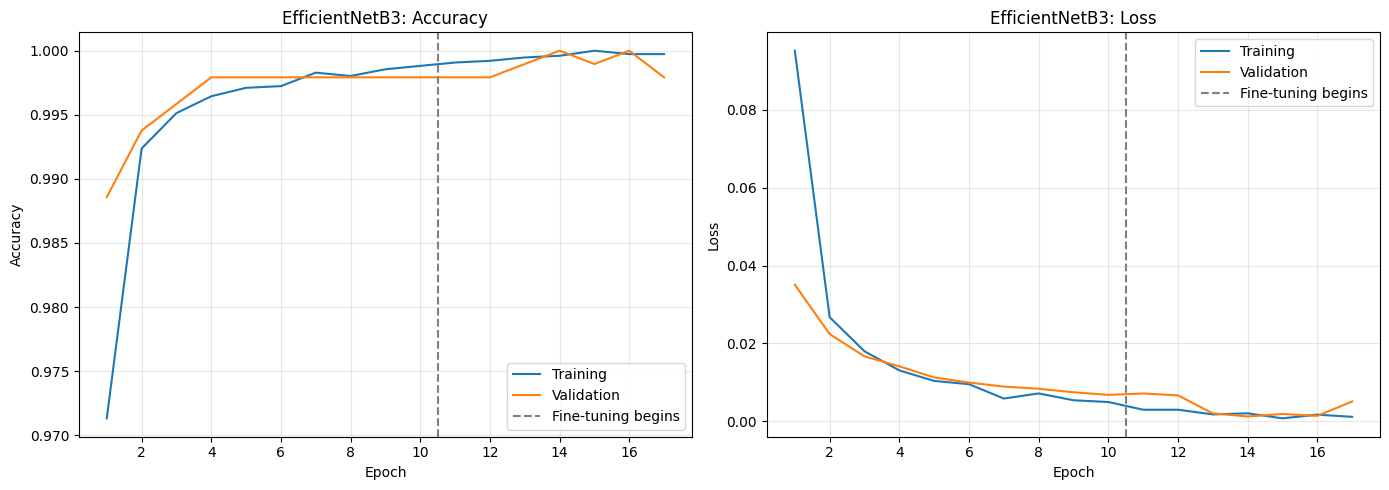

In [17]:

import matplotlib.pyplot as plt
import numpy as np

stage1 = history_effnet_stage1.history
stage2 = history_effnet_stage2.history

# Combine histories
train_acc = stage1["accuracy"] + stage2["accuracy"]
val_acc = stage1["val_accuracy"] + stage2["val_accuracy"]

train_loss = stage1["loss"] + stage2["loss"]
val_loss = stage1["val_loss"] + stage2["val_loss"]

epochs = np.arange(1, len(train_acc) + 1)
fine_tuning_start = len(stage1["accuracy"]) + 0.5

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(epochs, train_acc, label="Training")
axes[0].plot(epochs, val_acc, label="Validation")
axes[0].axvline(
    fine_tuning_start,
    linestyle="--",
    color="gray",
    label="Fine-tuning begins"
)
axes[0].set_title("EfficientNetB3: Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(epochs, train_loss, label="Training")
axes[1].plot(epochs, val_loss, label="Validation")
axes[1].axvline(
    fine_tuning_start,
    linestyle="--",
    color="gray",
    label="Fine-tuning begins"
)
axes[1].set_title("EfficientNetB3: Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/kaggle/working/effnet_training_curves.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


## 5. ConvNeXt-Tiny: Transfer learning

I also trained ConvNeXt-Tiny to compare a second pretrained architecture with EfficientNetB3. Although both models are CNNs, their different designs made them useful for comparing performance on the same dataset.

I replaced the original classifier with a two-class head and initially froze the backbone. As with EfficientNetB3, I restored the generator's scaled inputs to the 0–255 range for the backbone's built-in preprocessing.

In [18]:

from tensorflow.keras import Model, layers
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(40)

# Load the pretrained ConvNeXt-Tiny backbone
convnext_base = ConvNeXtTiny(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3),
    include_preprocessing=True
)

# Freeze the pretrained backbone
convnext_base.trainable = False

# Build the classification model
inputs = layers.Input(shape=(224, 224, 3))

# Our generator supplies images in [0, 1],
# while ConvNeXt's internal preprocessing expects [0, 255].
x = layers.Rescaling(255.0)(inputs)

x = convnext_base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(2, activation="softmax")(x)

convnext_model = Model(inputs, outputs)

convnext_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

convnext_model.summary()


111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convnext_tiny (Functional)      │ (None, 7, 7, 768)      │    27,820,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 768)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        98,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,918,818 (106.50 MB)

 Trainable params: 98,690 (385.51 KB)

 Non-trainable params: 27,820,128 (106.13 MB)

### 5.1 Stage 1: Training the ConvNeXt classification head

I trained the new classification head while keeping the ConvNeXt backbone frozen. I used validation-loss monitoring and checkpointing to save the best model from this stage.

In [19]:

convnext_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(model_dir / "convnext_stage1_best.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
]


In [20]:

history_convnext_stage1 = convnext_model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=10,
    callbacks=convnext_callbacks,
    verbose=1
)

print("ConvNeXt-Tiny Stage 1 training complete.")


Epoch 1/10


2026-10-17 13:14:38.692569: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 13:14:38.827854: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


285/380 ━━━━━━━━━━━━━━━━━━━━ 11s 117ms/step - accuracy: 0.8299 - loss: 0.3650

2026-10-17 13:15:18.718426: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 13:15:18.853395: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.8562 - loss: 0.3168

2026-10-17 13:15:44.560590: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 13:15:44.695042: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_loss improved from None to 0.04872, saving model to /kaggle/working/models/convnext_stage1_best.keras

Epoch 1: finished saving model to /kaggle/working/models/convnext_stage1_best.keras
380/380 ━━━━━━━━━━━━━━━━━━━━ 81s 174ms/step - accuracy: 0.9413 - loss: 0.1574 - val_accuracy: 0.9834 - val_loss: 0.0487
Epoch 2/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.9882 - loss: 0.0397
Epoch 2: val_loss improved from 0.04872 to 0.02761, saving model to /kaggle/working/models/convnext_stage1_best.keras

Epoch 2: finished saving model to /kaggle/working/models/convnext_stage1_best.keras
380/380 ━━━━━━━━━━━━━━━━━━━━ 44s 115ms/step - accuracy: 0.9909 - loss: 0.0329 - val_accuracy: 0.9917 - val_loss: 0.0276
Epoch 3/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.9952 - loss: 0.0191
Epoch 3: val_loss improved from 0.02761 to 0.01712, saving model to /kaggle/working/models/convnext_stage1_best.keras

Epoch 3: finished saving model to /kaggle/working/models/conv

### 5.2 Preparing ConvNeXt-Tiny for fine-tuning

I made the final 20 backbone layers eligible for fine-tuning but kept normalization layers frozen. I also lowered the learning rate to 0.00001, following the same general two-stage approach used for EfficientNetB3.

In [21]:

# Enable selective fine-tuning
convnext_base.trainable = True

# Freeze all backbone layers except the final 20
for layer in convnext_base.layers[:-20]:
    layer.trainable = False

# Keep normalization layers frozen
for layer in convnext_base.layers:
    if isinstance(
        layer,
        (tf.keras.layers.BatchNormalization,
         tf.keras.layers.LayerNormalization)
    ):
        layer.trainable = False

# Recompile with a smaller learning rate
convnext_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print(
    "Trainable backbone layers:",
    sum(layer.trainable for layer in convnext_base.layers)
)

print("Fine-tuning learning rate: 0.00001")


Trainable backbone layers: 17
Fine-tuning learning rate: 0.00001


In [22]:

convnext_ft_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(model_dir / "convnext_finetuned_best.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
]


### 5.3 Stage 2: Fine-tuning ConvNeXt-Tiny

I fine-tuned the selected backbone layers and classifier together, then saved the checkpoint with the lowest validation loss for final evaluation.

In [23]:

history_convnext_stage2 = convnext_model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=10,
    callbacks=convnext_ft_callbacks,
    verbose=1
)

print("ConvNeXt-Tiny fine-tuning complete.")


Epoch 1/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.9997 - loss: 0.0017
Epoch 1: val_loss improved from None to 0.00209, saving model to /kaggle/working/models/convnext_finetuned_best.keras

Epoch 1: finished saving model to /kaggle/working/models/convnext_finetuned_best.keras
380/380 ━━━━━━━━━━━━━━━━━━━━ 102s 221ms/step - accuracy: 0.9996 - loss: 0.0016 - val_accuracy: 0.9990 - val_loss: 0.0021
Epoch 2/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 1.0000 - loss: 5.2382e-04
Epoch 2: val_loss improved from 0.00209 to 0.00144, saving model to /kaggle/working/models/convnext_finetuned_best.keras

Epoch 2: finished saving model to /kaggle/working/models/convnext_finetuned_best.keras
380/380 ━━━━━━━━━━━━━━━━━━━━ 72s 188ms/step - accuracy: 1.0000 - loss: 4.8777e-04 - val_accuracy: 0.9990 - val_loss: 0.0014
Epoch 3/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 1.0000 - loss: 3.0382e-04
Epoch 3: val_loss did not improve from 0.00144
380/380 ━━━━━━━━━━━━━

### 5.4 ConvNeXt-Tiny training curves

I combined the histories from both training stages and marked the start of fine-tuning. This allowed me to compare how training and validation performance changed throughout the experiment.

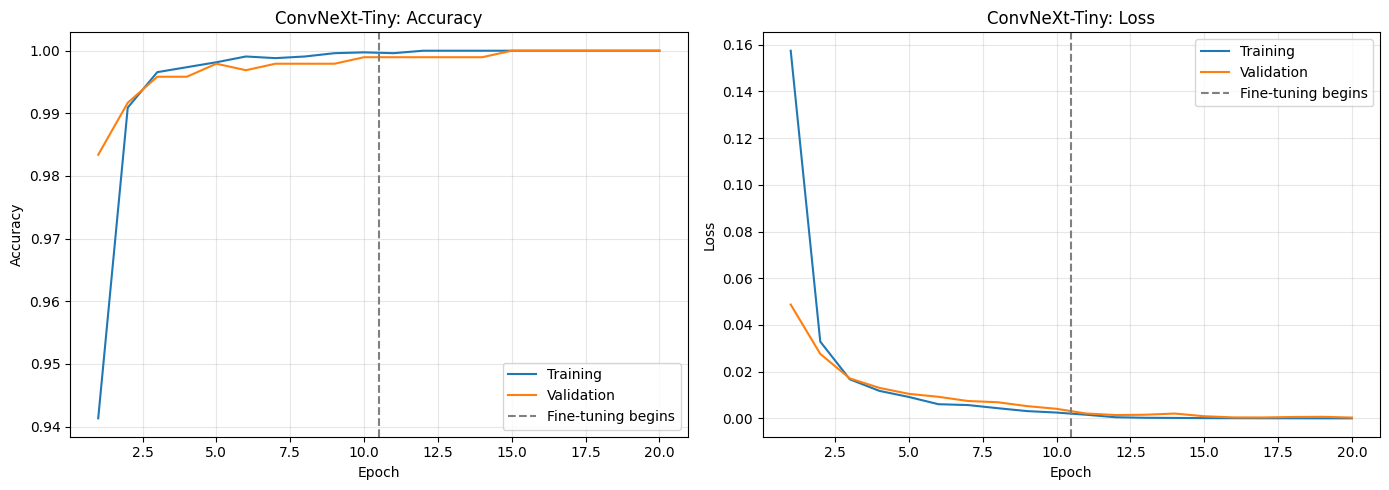

In [24]:

import matplotlib.pyplot as plt
import numpy as np

stage1 = history_convnext_stage1.history
stage2 = history_convnext_stage2.history

train_acc = stage1["accuracy"] + stage2["accuracy"]
val_acc = stage1["val_accuracy"] + stage2["val_accuracy"]

train_loss = stage1["loss"] + stage2["loss"]
val_loss = stage1["val_loss"] + stage2["val_loss"]

epochs = np.arange(1, len(train_acc) + 1)
fine_tuning_start = len(stage1["accuracy"]) + 0.5

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, train_acc, label="Training")
axes[0].plot(epochs, val_acc, label="Validation")
axes[0].axvline(
    fine_tuning_start,
    linestyle="--",
    color="gray",
    label="Fine-tuning begins"
)
axes[0].set_title("ConvNeXt-Tiny: Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, train_loss, label="Training")
axes[1].plot(epochs, val_loss, label="Validation")
axes[1].axvline(
    fine_tuning_start,
    linestyle="--",
    color="gray",
    label="Fine-tuning begins"
)
axes[1].set_title("ConvNeXt-Tiny: Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/convnext_training_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


## 6. Loading the trained models

I reloaded the saved baseline CNN and fine-tuned EfficientNetB3 and ConvNeXt-Tiny checkpoints before the final evaluation. This ensured that the comparison used the saved model files rather than whichever model objects remained in memory.

In [25]:

import tensorflow as tf

baseline_final = tf.keras.models.load_model(
    "/kaggle/working/baseline_cnn.keras"
)

effnet_final = tf.keras.models.load_model(
    "/kaggle/working/models/effnet_finetuned_best.keras"
)

convnext_final = tf.keras.models.load_model(
    "/kaggle/working/models/convnext_finetuned_best.keras"
)

print("All three models loaded successfully.")


All three models loaded successfully.


## 7. Final evaluation on the held-out test set

I evaluated all three models on the same 963 test images, reporting accuracy, loss, and precision, recall, and F1-score for adenocarcinoma (class 0). I included class-specific metrics because overall accuracy alone could hide mistakes in identifying cancerous tissue.

The baseline CNN achieved **99.27% test accuracy** and approximately **98.55% cancer recall**. EfficientNetB3 and ConvNeXt-Tiny both achieved **100.00% accuracy and cancer recall** on this test partition.

These results applied to the prepared LC25000 split only. Although Notebook 01 grouped visually similar images to reduce leakage, patient- and slide-level independence was not established, and the models were not tested on an external dataset.

In [26]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Baseline CNN": baseline_final,
    "EfficientNetB3": effnet_final,
    "ConvNeXt-Tiny": convnext_final
}

results = []

# Cancer is class 0 in our mapping
CANCER_CLASS = test_gen.class_indices["adenocarcinoma"]

for name, model in models.items():

    test_gen.reset()

    probabilities = model.predict(test_gen, verbose=1)
    predictions = np.argmax(probabilities, axis=1)
    actual = test_gen.classes

    loss, accuracy = model.evaluate(test_gen, verbose=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision (cancer)": precision_score(
            actual, predictions, pos_label=CANCER_CLASS
        ),
        "Recall (cancer)": recall_score(
            actual, predictions, pos_label=CANCER_CLASS
        ),
        "F1 (cancer)": f1_score(
            actual, predictions, pos_label=CANCER_CLASS
        ),
        "Test Loss": loss
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

results_df.to_csv(
    "/kaggle/working/final_model_comparison.csv",
    index=False
)


49/49 ━━━━━━━━━━━━━━━━━━━━ 13s 239ms/step
49/49 ━━━━━━━━━━━━━━━━━━━━ 24s 295ms/step
49/49 ━━━━━━━━━━━━━━━━━━━━ 13s 178ms/step


,Model,Accuracy,Precision (cancer),Recall (cancer),F1 (cancer),Test Loss
0,Baseline CNN,0.9927,1.0,0.9855,0.9927,0.0214
1,EfficientNetB3,1.0000,1.0,1.0000,1.0000,0.0002
2,ConvNeXt-Tiny,1.0000,1.0,1.0000,1.0000,0.0002


### 7.1 Comparing test-set confusion matrices

I compared confusion matrices to see whether either class was misclassified and to distinguish false positives from false negatives. The plots summarized errors on this test partition rather than performance in a clinical setting.

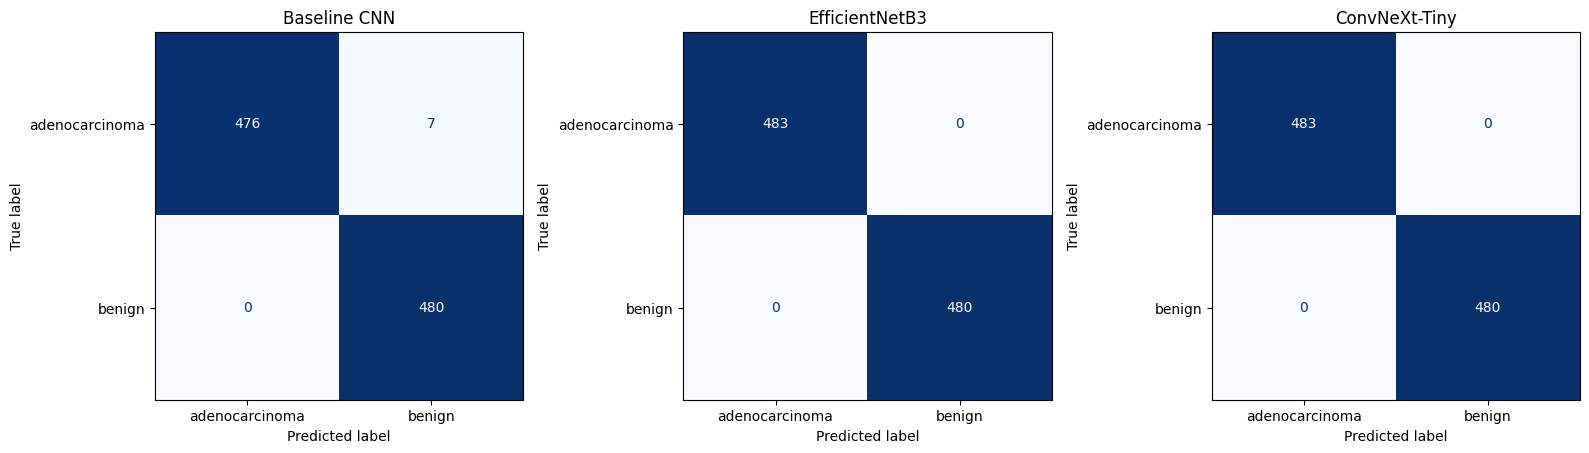

In [27]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = list(test_gen.class_indices.keys())

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, models.items()):

    test_gen.reset()

    probabilities = model.predict(test_gen, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    cm = confusion_matrix(
        test_gen.classes,
        predictions,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/final_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


## 8. Saving project outputs

I packaged the saved models, comparison table, and figures into a ZIP archive so I could reuse the results in Notebook 03 without repeating the training experiments.

## 9. Summary and limitations

All three models performed well on the held-out test images, with EfficientNetB3 and ConvNeXt-Tiny achieving identical test accuracy. However, I used only one dataset and one split, without external validation or random image augmentation. I also did not test calibration or robustness to changes in staining and image collection.

Because accuracy alone did not explain which parts of an image influenced a prediction, I explored Grad-CAM++ and quantitative faithfulness measures in Notebook 03. These analyses provided additional information about model behaviour but did not establish clinical reliability.

In [28]:

from pathlib import Path
import zipfile

working_dir = Path("/kaggle/working")
zip_path = working_dir / "colon_project_results.zip"

files_to_save = [
    "baseline_cnn.keras",
    "models/effnet_stage1_best.keras",
    "models/effnet_finetuned_best.keras",
    "models/convnext_stage1_best.keras",
    "models/convnext_finetuned_best.keras",
    "final_model_comparison.csv",
    "final_confusion_matrices.png",
    "effnet_training_curves.png",
    "convnext_training_curves.png"
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in files_to_save:
        filepath = working_dir / filename

        if filepath.exists():
            zipf.write(filepath, arcname=filename)
            print("Saved:", filename)
        else:
            print("Missing:", filename)

print("\nZIP file created:", zip_path)
print("Size:", round(zip_path.stat().st_size / (1024**2), 1), "MB")


Saved: baseline_cnn.keras
Saved: models/effnet_stage1_best.keras
Saved: models/effnet_finetuned_best.keras
Saved: models/convnext_stage1_best.keras
Saved: models/convnext_finetuned_best.keras
Saved: final_model_comparison.csv
Saved: final_confusion_matrices.png
Saved: effnet_training_curves.png
Saved: convnext_training_curves.png

ZIP file created: /kaggle/working/colon_project_results.zip
Size: 453.6 MB


## Source acknowledgement

The baseline CNN was adapted from the `Detection.ipynb` implementation associated with Li (2025). I used it as a starting point for the baseline architecture and documented the additional model comparisons and evaluations in this project.

**Reference (APA):**

Li, J. (2025). *CNN-based colon cancer detection – Python code*. https://doi.org/10.7910/DVN/B7OXBS